## Autoencoder for Spectral Data

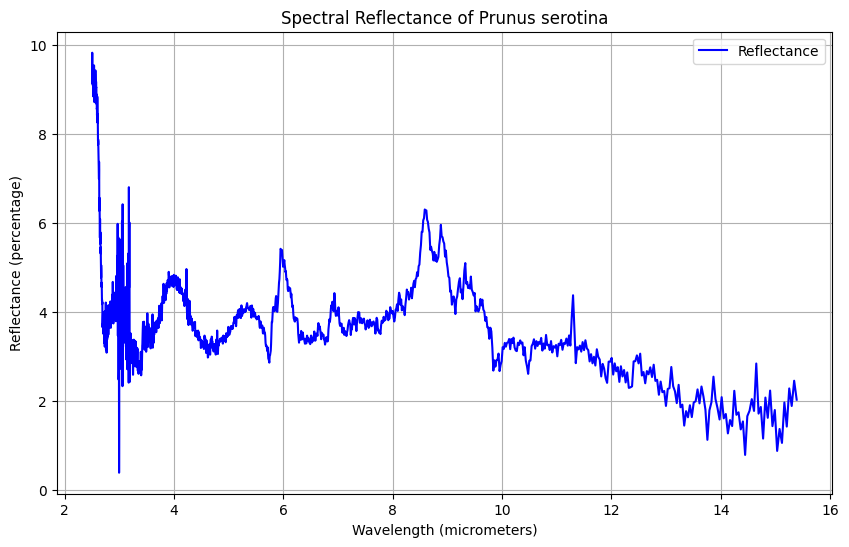

{
    "Name": "Prunus serotina",
    "Type": "Vegetation",
    "Class": "Tree",
    "Genus": "Prunus",
    "Species": "serotina",
    "Sample No.": "PRSE-2-65",
    "Owner": "UCSB",
    "Wavelength Range": "TIR",
    "Origin": "USA; Massachusetts; Harvard Forest",
    "Collection Date": "7/8/2013",
    "Description": "Samples were collected as part of NSF Macrosystem Biology proposal titled: Collaborative Research: Thermal controls on ecosystem metabolism and function: scaling from leaves to canopies to regions. Samples were collected and overnighted to JPL facilities for processing. The same leaves were processed in the Nicolet and then measured using the ASD.",
    "Measurement": "Hemispherical reflectance",
    "First Column": "X",
    "Second Column": "Y",
    "X Units": "Wavelength (micrometers)",
    "Y Units": "Reflectance (percentage)",
    "First X Value": "2.501",
    "Last X Value": "15.387",
    "Number of X Values": "1737",
    "Additional Information": "vegetation.tree.pr

In [1]:
from net.spec_utils import parse_spectral_file
import matplotlib.pyplot as plt
import json 


spectra_file = 'vegetation.tree.prunus.serotina.tir.prse-2-65.ucsb.nicolet.spectrum.txt'
spectra_files_dir = 'ecospeclib-all'
metadata, wavelengths, reflectances = parse_spectral_file(spectra_file, spectra_files_dir)

# Plotting the spectral data
plt.figure(figsize=(10, 6))
plt.plot(wavelengths, reflectances, label="Reflectance", color='blue')
plt.xlabel(metadata['X Units'])
plt.ylabel(metadata['Y Units'])
plt.title(f"Spectral Reflectance of {metadata['Name']}")
plt.grid(True)
plt.legend()
plt.show()
print(json.dumps(metadata, indent=4))

In [2]:
from net.spec_utils import parse_and_store_spectral_data

required_keys = ['Name', 'Type', 'Class', 'Genus', 'Species']

spectral_df = parse_and_store_spectral_data(required_keys, spectra_files_dir)
spectral_df

,Name,Type,Class,Genus,Species,normalized_reflectances,wavelengths
0,Arctostaphylos glandulosa 2,vegetation,Shrub,Arctostaphylos,glandulosa,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.006726457399103, 1.0134529147982063, 1..."
1,Misc Grass Litter - Mostly decomposed,non photosynthetic vegetation,leaves,none,none,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.006726457399103, 1.0134529147982063, 1..."
2,Quercus douglasii 2,vegetation,Tree,Quercus,douglasii,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.006726457399103, 1.0134529147982063, 1..."
3,Ceanothus megacarpus 3,vegetation,Shrub,Ceanothus,megacarpus,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.006726457399103, 1.0134529147982063, 1..."
4,Pinus lambertiana 1,vegetation,Tree,Pinus,lambertiana,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.006726457399103, 1.0134529147982063, 1..."
...,...,...,...,...,...,...,...
1158,Quercus suber,vegetation,Tree,Quercus,suber,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.006726457399103, 1.0134529147982063, 1..."
1159,Abies concolor 2,vegetation,Tree,Abies,concolor,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.006726457399103, 1.0134529147982063, 1..."
1160,Abies concolor 1,vegetation,Tree,Abies,concolor,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.006726457399103, 1.0134529147982063, 1..."
1161,Quercus agrifolia,vegetation,Tree,Quercus,agrifolia,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.006726457399103, 1.0134529147982063, 1..."


Training set shape: (651, 224, 1)
Validation set shape: (163, 224, 1)
Test set shape: (349, 224, 1)
Number of features: 224


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (1, 224, 1)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (1, 224, 16)           │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (1, 112, 16)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 112, 16)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (1, 112, 8)            │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (1, 56, 8)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (1, 56, 8)             │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d (UpSampling1D)    │ (1, 112, 8)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (1, 112, 8)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (1, 112, 16)           │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_1 (UpSampling1D)  │ (1, 224, 16)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (1, 224, 1)            │            49 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,105 (4.32 KB)

 Trainable params: 1,105 (4.32 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0080 - val_loss: 6.8921e-04 - learning_rate: 0.0100
Epoch 2/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.6873e-04 - val_loss: 7.6004e-05 - learning_rate: 0.0100
Epoch 3/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.6593e-05 - val_loss: 9.5235e-06 - learning_rate: 0.0100
Epoch 4/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.8242e-06 - val_loss: 1.1805e-06 - learning_rate: 0.0100
Epoch 5/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.7756e-07 - val_loss: 1.1495e-07 - learning_rate: 0.0100
Epoch 6/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.8410e-08 - val_loss: 1.5052e-08 - learning_rate: 0.0100
Epoch 7/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 9.0423e-09 - val_loss: 1.9471e-09 - learning_rate: 0.0100
Epoch 8/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.6319e-09 - val_loss: 6.0719e-10 - learning_rate: 0.0020
Epoch 9/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.2300e-1

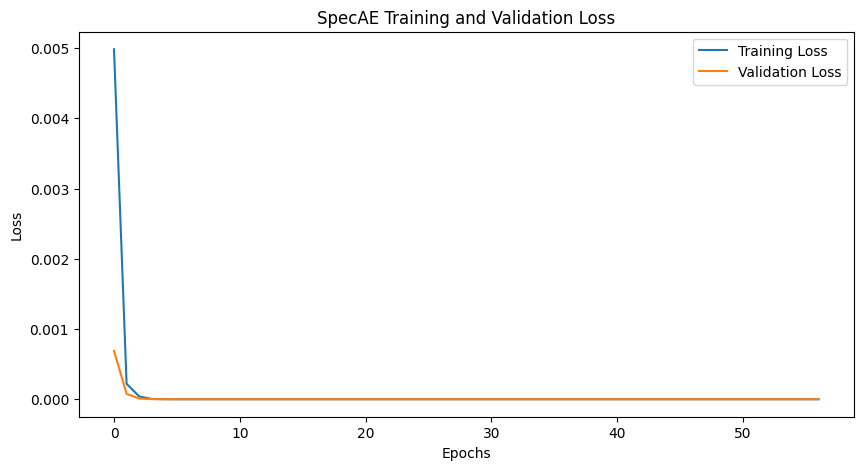

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 986us/step - loss: 0.0000e+00
Test set loss: 0.0


In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from net.spec_net import reduce_lr, early_stopping


X_data_normalized = np.array(spectral_df['normalized_reflectances'].tolist())
X_data_normalized = X_data_normalized.reshape((*X_data_normalized.shape, 1))


# Encode labels
spectral_df['combined_labels'] = spectral_df.apply(lambda row: ' '.join([str(row[col]) for col in ['Name', 'Type', 'Class', 'Genus', 'Species']]), axis=1)
encoder = LabelEncoder()
spectral_df['label_encoded'] = encoder.fit_transform(spectral_df['combined_labels'])


X_train, X_test, y_train, y_test = train_test_split(X_data_normalized, spectral_df['label_encoded'], test_size=0.3, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape: {X_test.shape}")


num_features = X_data_normalized.shape[1]
spectra_input_shape = (num_features, 1)
print(f"Number of features: {num_features}")


from net.spec_net import spec_AE


spectral_AE, spec_latent = spec_AE(spectra_input_shape, learning_rate=0.01, dropout_rate=0.3, l2_penalty=0.001)

history = spectral_AE.fit(X_train, X_train, # autoencoders typically use the input as the target for training   
                          epochs=100,
                          batch_size=32,
                          validation_data=(X_val, X_val),
                          callbacks=[reduce_lr, early_stopping])

# Plotting the training and validation loss
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('SpecAE Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


test_loss = spectral_AE.evaluate(X_test, X_test)
print(f"Test set loss: {test_loss}")

spectral_AE.save('models/spectral_AE.keras')


## 3D-Autoencoder for Hyperspectral Images

Datasets loaded:
Training annotations: dict_keys(['id', 'fruit', 'side', 'day', 'camera_type', 'files']) 636
Validation annotations: dict_keys(['id', 'fruit', 'side', 'day', 'camera_type', 'files']) 123
Test annotations: dict_keys(['id', 'fruit', 'side', 'day', 'camera_type', 'files']) 259
Input Shape: (64, 64, 224)


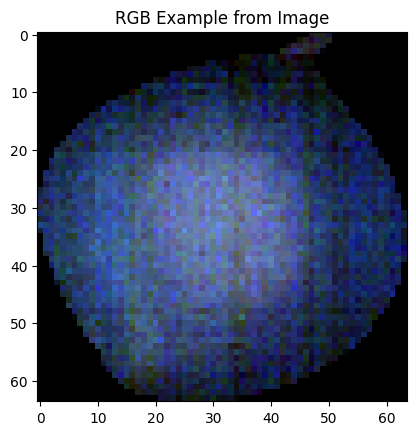

In [5]:
from net import hsi_utils
import matplotlib.pyplot as plt


DeepHS_dir = 'DeepHS'
# Using existing splits from DeepHS dataset
training_annotations, validation_annotations, test_annotations = hsi_utils.load_DeepHS_images(DeepHS_dir)

# Sample File
max_bands = 224  
data_file = training_annotations['records'][500]["files"]["data_file"]
hdr_file = training_annotations['records'][500]["files"]["header_file"]

hs_image, rgb_example = hsi_utils.read_and_visualize_hyperspectral_image(DeepHS_dir, data_file, hdr_file, max_bands)
print(f'Input Shape: {hs_image.shape}')

plt.imshow(rgb_example)
plt.title('RGB Example from Image')
plt.show()

Batch size: 32
Selected fruits: ['Mango', 'Kaki', 'Papaya', 'Kiwi', 'Avocado']
Total batches: 20


Shape of X_batch: (32, 64, 64, 224, 1)


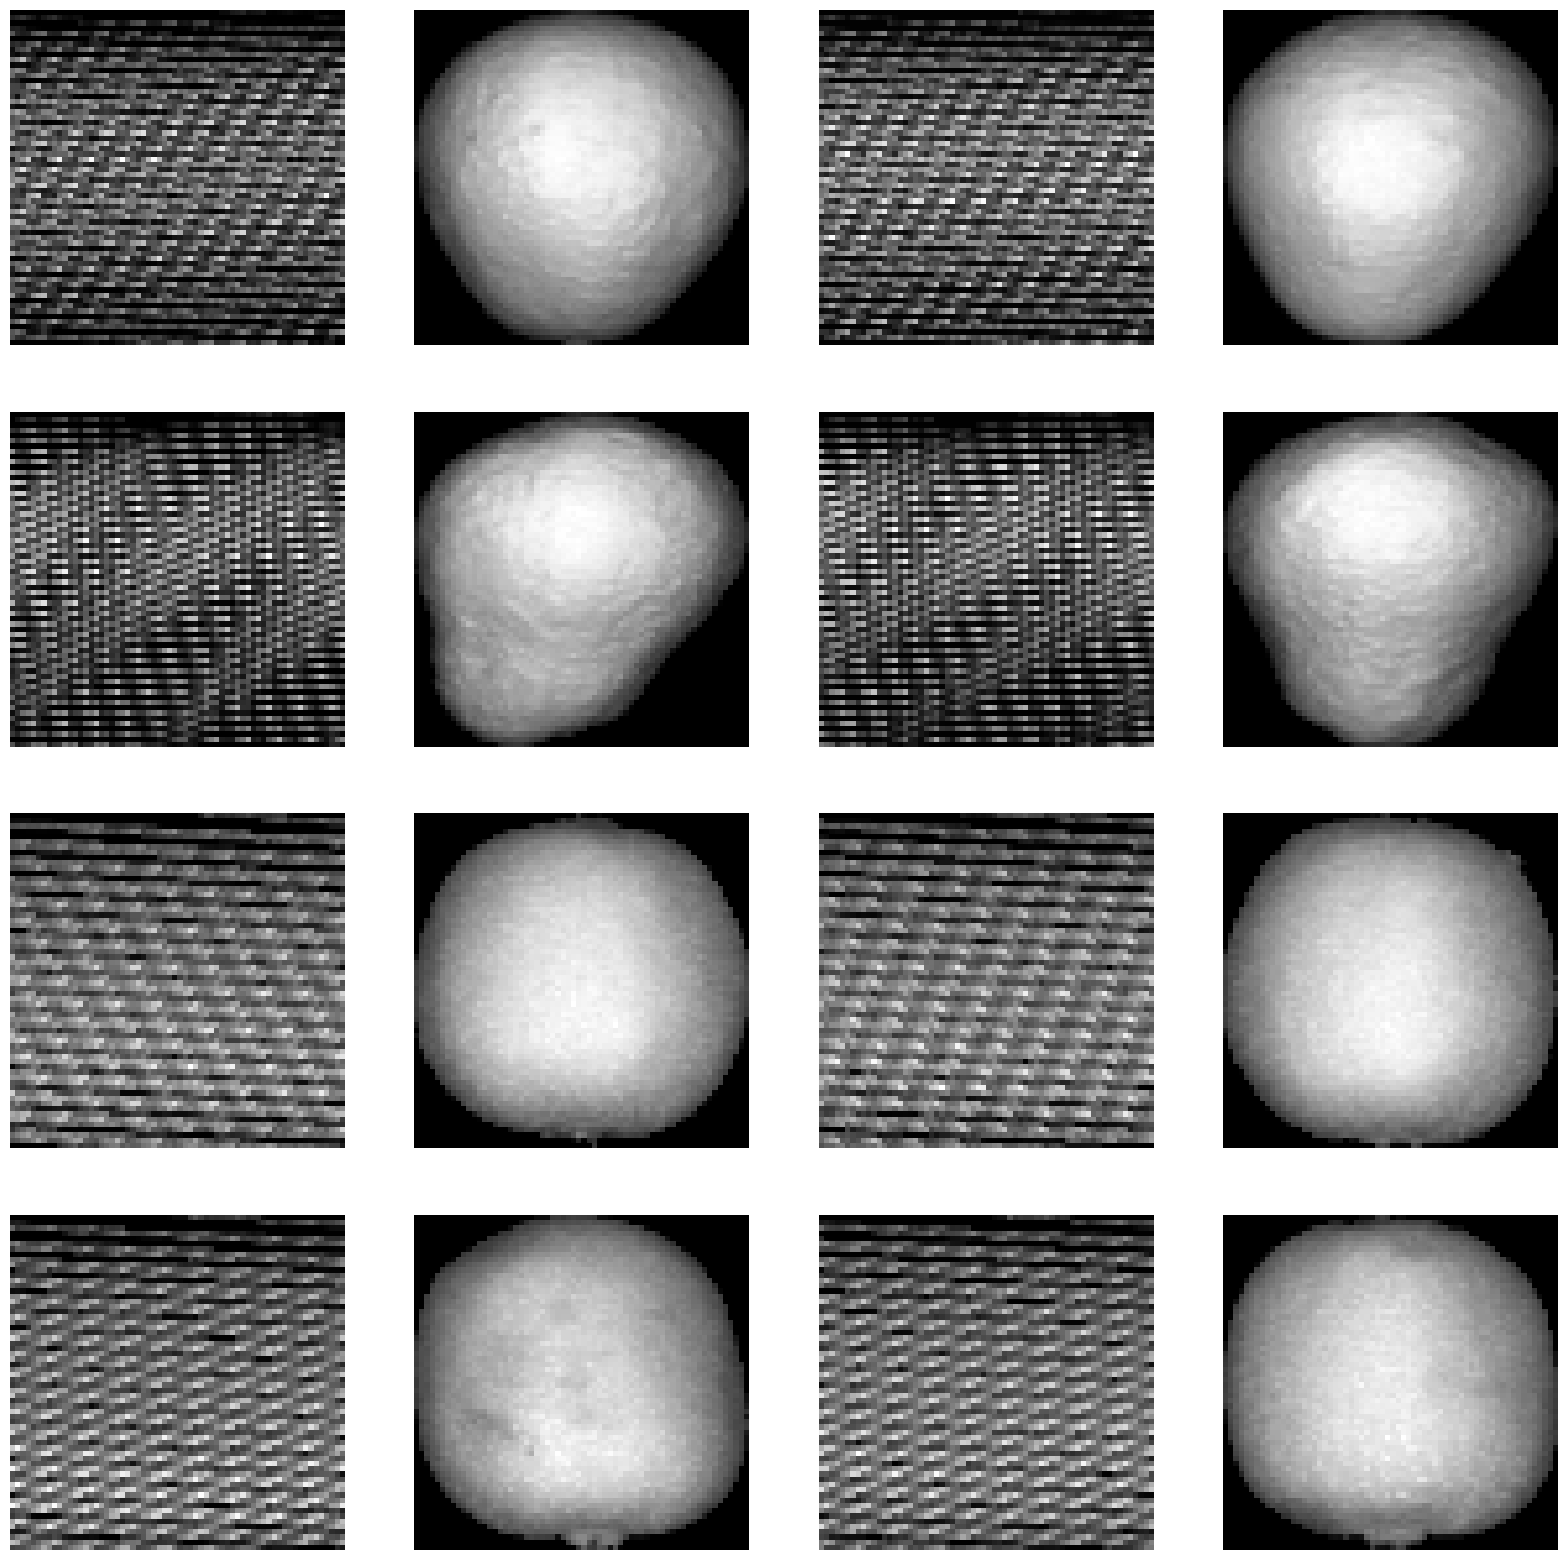

In [6]:
from sklearn.preprocessing import StandardScaler
from net.hsi_sequence import HyperspectralSequence
import matplotlib.pyplot as plt
import numpy as np

selected_fruits = ['Mango', 'Kaki','Papaya', 'Kiwi', 'Avocado']

batch_size = 32
max_bands = 224

hsi_train_sequence = HyperspectralSequence(training_annotations, DeepHS_dir, selected_fruits, batch_size, max_bands)
hsi_val_sequence = HyperspectralSequence(validation_annotations, DeepHS_dir, selected_fruits, batch_size, max_bands)
hsi_test_sequence = HyperspectralSequence(test_annotations, DeepHS_dir, selected_fruits, batch_size, max_bands)

print("Batch size:", hsi_train_sequence.batch_size)
print("Selected fruits:", hsi_train_sequence.selected_fruits)
print("Total batches:", len(hsi_train_sequence))

# Single batch of data
X_batch, _ = hsi_train_sequence[0]  
hsi_input_shape = X_batch.shape[1:]
print("Shape of X_batch:", X_batch.shape)

def plot_band(X_batch, band_number):
    fig, axes = plt.subplots(4, 4, figsize=(20, 20))
    for i, ax in enumerate(axes.flat):
        ax.imshow(X_batch[i, :, :, band_number, 0], cmap='gray')
        ax.axis('off')
    plt.show()

plot_band(X_batch, 189)

In [7]:
from net.hsi_net import hsi_3dAE
print(X_batch.shape[1:])

hsi_3D_AE, hsi_latent = hsi_3dAE(input_shape=hsi_input_shape)
hsi_3D_AE.compile(optimizer='adam', loss='mean_squared_error')
hsi_3D_AE.summary()

#hsi_3D_AE.fit(hsi_train_sequence, validation_data=hsi_val_sequence, verbose=1, epochs=10)
#hsi_3D_AE.save(f'models/hsi_3D_AE{selected_fruits}.keras')

(64, 64, 224, 1)


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 224, 1) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d (Conv3D)                 │ (None, 64, 64, 224,    │           588 │
│                                 │ 21)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 64, 64, 224,    │         1,859 │
│                                 │ 11)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 64, 64, 224, 7) │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 32, 32, 112, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 802816)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │   102,760,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 802816)         │     2,408,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 32, 32, 112, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling3d (UpSampling3D)    │ (None, 64, 64, 224, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding3d (ZeroPadding3D)  │ (None, 65, 65, 225, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cropping3d (Cropping3D)         │ (None, 64, 64, 224, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose                │ (None, 64, 64, 224, 7) │            56 │
│ (Conv3DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_1              │ (None, 64, 64, 224,    │           627 │
│ (Conv3DTranspose)               │ 11)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_2              │ (None, 64, 64, 224, 1) │           298 │
│ (Conv3DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,181,330 (401.23 MB)

 Trainable params: 105,181,330 (401.23 MB)

 Non-trainable params: 0 (0.00 B)

## CCA_DCCA

In [8]:
from net.cca_dcca_net import CCA_DCCA

print(X_batch.shape)
print(spectra_input_shape)

# Need to further define the CCA_DCCA model or consider something else like VAE
cca_dcca_model = CCA_DCCA(hsi_input_shape=X_batch.shape[1:], spectral_input_shape=spectra_input_shape)
cca_dcca_model.compile(optimizer='adam')

# cca_dcca_model.fit([hsi_train_sequence, X_train], validation_data=([hsi_val_sequence, X_val]), verbose=1, epochs=10)

(32, 64, 64, 224, 1)
(224, 1)


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 224, 1) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_3 (Conv3D)               │ (None, 64, 64, 224,    │           588 │
│                                 │ 21)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_4 (Conv3D)               │ (None, 64, 64, 224,    │         1,859 │
│                                 │ 11)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_5 (Conv3D)               │ (None, 64, 64, 224, 7) │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 32, 32, 112, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 802816)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │   102,760,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 2)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 802816)         │     2,408,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 32, 32, 112, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling3d_1 (UpSampling3D)  │ (None, 64, 64, 224, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding3d_1                │ (None, 65, 65, 225, 7) │             0 │
│ (ZeroPadding3D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cropping3d_1 (Cropping3D)       │ (None, 64, 64, 224, 7) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_3              │ (None, 64, 64, 224, 7) │            56 │
│ (Conv3DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_4              │ (None, 64, 64, 224,    │           627 │
│ (Conv3DTranspose)               │ 11)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_transpose_5              │ (None, 64, 64, 224, 1) │           298 │
│ (Conv3DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,181,330 (401.23 MB)

 Trainable params: 105,181,330 (401.23 MB)

...

Model: "cca_dcca__model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional_5 (Functional)       │ ?                      │   105,181,330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_7 (Functional)       │ ?                      │         1,105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,182,435 (401.24 MB)

 Trainable params: 105,182,435 (401.24 MB)

 Non-trainable params: 0 (0.00 B)

## Variational Autoencoder

### Hyperspectral 3D Variational Autoencoder

(64, 64, 224, 1)


Model: "hsi_vae"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 64, 64,    │          0 │ -                 │
│ (InputLayer)        │ 224, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_6 (Conv3D)   │ (None, 64, 64,    │        588 │ input_layer_4[0]… │
│                     │ 224, 21)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_7 (Conv3D)   │ (None, 64, 64,    │      1,859 │ conv3d_6[0][0]    │
│                     │ 224, 11)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_8 (Conv3D)   │ (None, 64, 64,    │         84 │ conv3d_7[0][0]    │
│                     │ 224, 7)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_2     │ (None, 32, 32,    │          0 │ conv3d_8[0][0]    │
│ (MaxPooling3D)      │ 112, 7)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 802816)    │          0 │ max_pooling3d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │ 102,760,5… │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 8)         │      1,032 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 8)         │      1,032 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Lambda)          │ (None, 8)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 229376)    │  2,064,384 │ z[0][0]           │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 16, 16,    │          0 │ dense_11[0][0]    │
│                     │ 56, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_transpose_6  │ (None, 16, 16,    │        119 │ reshape_2[0][0]   │
│ (Conv3DTranspose)   │ 56, 7)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling3d_2     │ (None, 32, 32,    │          0 │ conv3d_transpose… │
│ (UpSampling3D)      │ 112, 7)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_transpose_7  │ (None, 32, 32,    │        627 │ up_sampling3d_2[… │
│ (Conv3DTranspose)   │ 112, 11)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling3d_3     │ (None, 64, 64,    │          0 │ conv3d_transpose… │
│ (UpSampling3D)      │ 224, 11)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_transpose_8  │ (None, 64, 64,    │      6,258 │ up_sampling3d_3[… │
│ (Conv3DTranspose)   │ 224, 21)          │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 104,836,559 (399.92 MB)

 Trainable params: 104,836,559 (399.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 565s 28s/step - loss: 0.1359 - val_loss: 0.1389
Epoch 2/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 561s 28s/step - loss: 0.1337 - val_loss: 0.1307
Epoch 3/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 561s 28s/step - loss: 0.1169 - val_loss: 0.0970
Epoch 4/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 562s 28s/step - loss: 0.0782 - val_loss: 0.0692
Epoch 5/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 561s 28s/step - loss: 0.0596 - val_loss: 0.0620


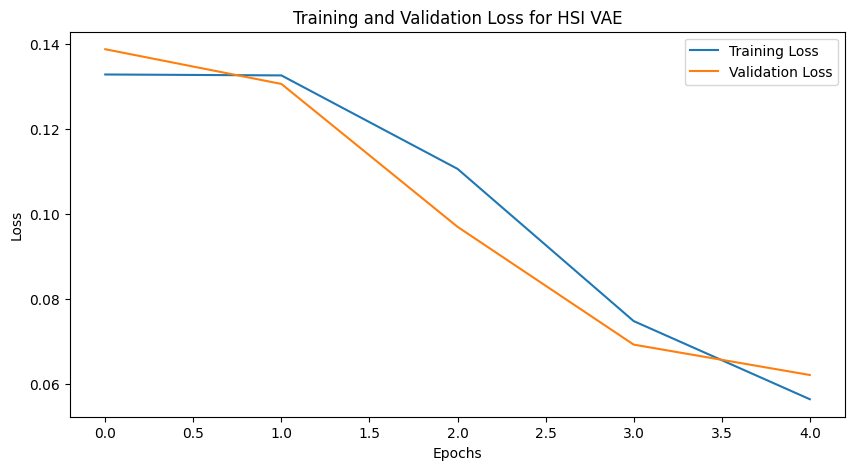

In [9]:
from net.hsi_vae_net import hsi_VAE 
print(hsi_input_shape)
hsi_vae = hsi_VAE(input_shape=hsi_input_shape)

history = hsi_vae.fit(
    hsi_train_sequence,
    epochs=5,
    batch_size=batch_size,
    validation_data=hsi_val_sequence,
    callbacks=[early_stopping],
)


plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss for HSI VAE')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

hsi_vae.save(f'models/hsi_3D_VAE{selected_fruits}.keras')

### Spectral Variational Autoencoder

(224, 1)


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 224, 16)   │         64 │ input_layer_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 112, 16)   │          0 │ conv1d_10[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 112, 16)   │          0 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 112, 8)    │        392 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 56, 8)     │          0 │ conv1d_11[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 448)       │          0 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 8)         │      3,592 │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 8)         │      3,592 │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 8)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 448)       │      4,032 │ lambda[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 56, 8)     │          0 │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling1d_4     │ (None, 112, 8)    │          0 │ reshape_3[0][0]   │
│ (UpSampling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 112, 8)    │        200 │ up_sampling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling1d_5     │ (None, 224, 8)    │          0 │ conv1d_12[0][0]   │
│ (UpSampling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 224, 16)   │        400 │ up_sampling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 224, 1)    │         49 │ conv1d_13[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vae_loss (VAELoss)  │ (None, 224, 1)    │          0 │ input_layer_5[0]… │
│                     │                   │            │ conv1d_14[0][0],  │
│                     │                   │            │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,321 (48.13 KB)

 Trainable params: 12,321 (48.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.2493 - val_loss: 0.2020 - learning_rate: 0.0010
Epoch 2/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1785 - val_loss: 0.0902 - learning_rate: 0.0010
Epoch 3/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0677 - val_loss: 0.0168 - learning_rate: 0.0010
Epoch 4/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0121 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 5/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0050 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 6/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0032 - val_loss: 0.0025 - learning_rate: 0.0010
Epoch 7/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0023 - val_loss: 0.0018 - learning_rate: 0.0010
Epoch 8/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0017 - val_loss: 0.0013 - learning_rate: 0.0010
Epoch 9/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0012 - val_loss: 9.6268e-04 - learning_rate: 0.0010
Epoch 1

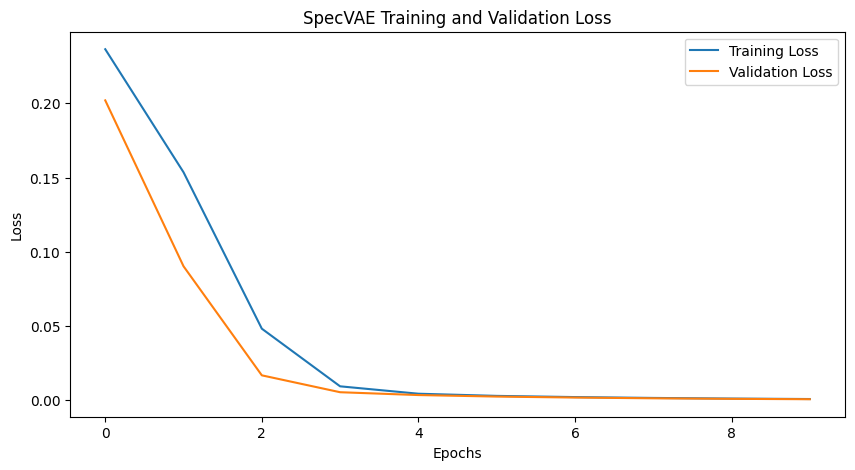

In [10]:
from net.spec_vae_net import spec_VAE
print(spectra_input_shape)


spectra_input_shape = (num_features, 1)  
learning_rate = 0.001

spectral_VAE = spec_VAE(spectra_input_shape, learning_rate=learning_rate, dropout_rate=0.3, l2_penalty=0.001)

history = spectral_VAE.fit(X_train, X_train, 
                           epochs=500, 
                           batch_size=28, 
                           validation_data=(X_val, X_val), 
                           callbacks=[reduce_lr, early_stopping])


plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('SpecVAE Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


spectral_VAE.save(f'models/spectral_VAE{selected_fruits}.keras')

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Optimal number of clusters: 2


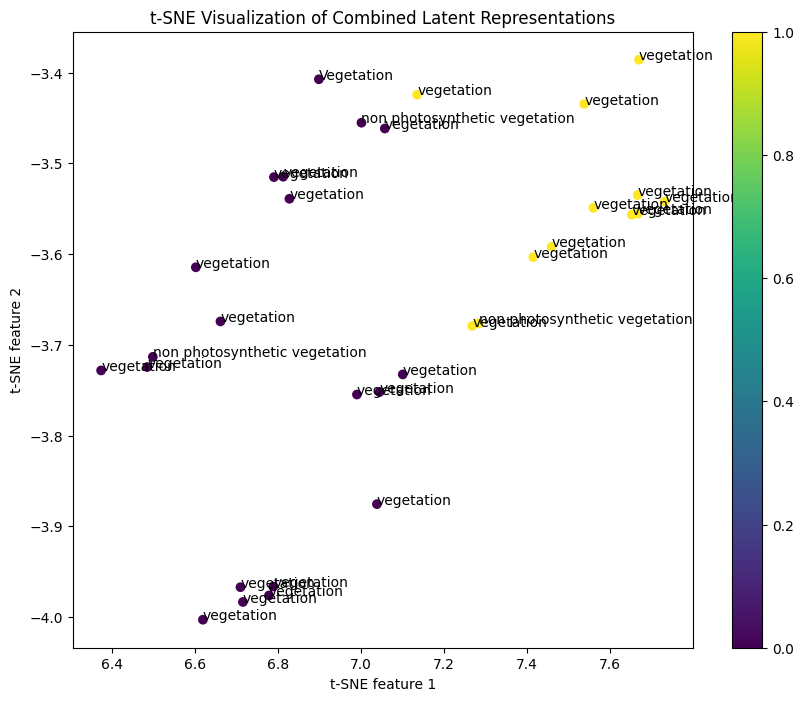

In [11]:
from tensorflow.keras.models import Model
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Function to find optimal number of clusters
def find_optimal_clusters(data, max_k):
    wcss = []
    silhouette_scores = []
    k_values = list(range(2, max_k + 1))

    # Compute WCSS and silhouette scores
    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=42)
        cluster_labels = kmeans.fit_predict(data)
        wcss.append(kmeans.inertia_)
        silhouette_scores.append(silhouette_score(data, cluster_labels))

    # The "elbow" is optimal k
    elbow_value = np.argmin(np.gradient(wcss))

    # Find the number of clusters with the highest silhouette score around the elbow
    optimal_k = k_values[elbow_value + np.argmax(silhouette_scores[elbow_value:])]

    return optimal_k, wcss, silhouette_scores


# batch from test sequence a
hsi_data = hsi_test_sequence[0][0] 
spectral_data = X_test  # This can be used directly for predictions

# Encoder models
hsi_encoder_model = Model(inputs=hsi_vae.input, outputs=hsi_vae.get_layer('z_mean').output)
spectral_encoder_model = Model(inputs=spectral_VAE.input, outputs=spectral_VAE.get_layer('z_mean').output)

#'hsi_test_sequence' is a batch from the HSI data
hsi_data_batch = hsi_test_sequence[0][0]  # Hyperspectral data from the first batch

# select the same number of samples from the spectral data as in the HSI batch
spectral_data_subset = spectral_data[:hsi_data_batch.shape[0]]

# predict latent representations
hsi_latent = hsi_encoder_model.predict(hsi_data_batch)
spectral_latent = spectral_encoder_model.predict(spectral_data_subset)

# concatenate to same number of samples
combined_latent = np.concatenate([hsi_latent, spectral_latent], axis=1)

# Find the optimal number of clusters
optimal_k, _, _ = find_optimal_clusters(combined_latent, max_k=20)
print(f"Optimal number of clusters: {optimal_k}")

# Perform KMeans clustering with the optimal number of clusters found
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
cluster_labels = kmeans.fit_predict(combined_latent)

# Perform t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(combined_latent)

# scatter plot of the t-SNE results
plt.figure(figsize=(10, 8))
scatter = plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=cluster_labels, cmap='viridis')
plt.colorbar()

# choose column from spectral_df and align with indices of spectral_data
for i, txt in enumerate(cluster_labels):
    plt.annotate(spectral_df['Type'].iloc[i], (tsne_results[i, 0], tsne_results[i, 1]))

plt.xlabel('t-SNE feature 1')
plt.ylabel('t-SNE feature 2')
plt.title('t-SNE Visualization of Combined Latent Representations')
plt.show()


### PCA reduced 2D Variational Autoencoder

In [12]:
import numpy as np
import random

def load_sample_data_for_pca(image_paths, sample_size=100):
    """
    Load a random sample of hyperspectral images to fit PCA.
    
    Parameters:
        image_paths (list of str): List of paths to the hyperspectral image files.
        sample_size (int): Number of images to sample for PCA fitting.
    
    Returns:
        np.array: Array containing the sampled image data, reshaped and possibly padded for PCA.
    """

    sampled_paths = random.sample(image_paths, sample_size)
    sample_data = np.empty((sample_size, 128, 128, 224), dtype=np.float32)  
    
    for i, path in enumerate(sampled_paths):
        try:
            image = np.load(path)
            if image.shape == (202, 128, 128):
                # Transpose the dimensions to bring bands to the last dimension
                image = np.transpose(image, (1, 2, 0))
                # Pad the spectral dimension from 202 to 224 
                padding = 224 - image.shape[2]
                if padding > 0:
                    image = np.pad(image, pad_width=((0, 0), (0, 0), (0, padding)), mode='constant', constant_values=0)
                sample_data[i] = image
            else:
                print(f"Skipping image {path} due to shape mismatch: expected (202, 128, 128), got {image.shape}")
        except Exception as e:
            print(f"Error loading image {path}: {e}")
    
    # Reshape data for PCA fitting: (n_samples, n_features)
    sample_data = sample_data.reshape(-1, 224)  # n_features = 224 (the spectral dimension after padding, matches largest image depth)
    
    return sample_data


In [13]:
from net.hyspec_hsi_utils import load_hyspecnet_images
from sklearn.decomposition import PCA

HySpecNet_dir = 'HySpecNet'

training_paths, validation_paths, test_paths = load_hyspecnet_images(HySpecNet_dir)

print("Training paths:", training_paths[:5]) 
print("Validation paths:", validation_paths[:5]) 
print("Test paths:", test_paths[:5])  

sample_data = load_sample_data_for_pca(training_paths, sample_size=100)  # Adjust based on memory

def fit_pca(data, n_components=30):
    pca = PCA(n_components=n_components)
    pca.fit(data)
    return pca

# Fit PCA
pca_model = fit_pca(sample_data, n_components=30)

from net.hyspec_hsi_sequence import PCASpectralImageDataGenerator


hyspec_train_gen = PCASpectralImageDataGenerator(training_paths, pca=pca_model, batch_size=32)
hyspec_val_gen = PCASpectralImageDataGenerator(validation_paths, pca=pca_model, batch_size=32)
hyspec_test_gen = PCASpectralImageDataGenerator(test_paths, pca=pca_model, batch_size=32)


X_sample, _ = hyspec_train_gen[0]

print("Shape of the data from generator:", X_sample.shape)
print("Number of batches in the training generator:", len(hyspec_train_gen))
print("Number of batches in the validation generator:", len(hyspec_val_gen))
print("Number of batches in the test generator:", len(hyspec_test_gen))

Training paths: ['HySpecNet/hyspecnet-11k/patches/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z-Y01460273_X06950822/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z-Y01460273_X06950822-DATA.npy', 'HySpecNet/hyspecnet-11k/patches/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z-Y02740401_X04390566/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z-Y02740401_X04390566-DATA.npy', 'HySpecNet/hyspecnet-11k/patches/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z-Y02740401_X05670694/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z-Y02740401_X05670694-DATA.npy', 'HySpecNet/hyspecnet-11k/patches/ENMAP01-____L2A-DT00000

Model: "hyspec_hsi_vae"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 30)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      5,691 │ input_layer_7[0]… │
│                     │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │        935 │ conv2d_3[0][0]    │
│                     │ 11)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 128,  │         84 │ conv2d_4[0][0]    │
│                     │ 7)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64, 7) │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_5 (Flatten) │ (None, 28672)     │          0 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 128)       │  3,670,144 │ flatten_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 8)         │      1,032 │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 8)         │      1,032 │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Lambda)          │ (None, 8)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 28672)     │    258,048 │ z[0][0]           │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_5 (Reshape) │ (None, 64, 64, 7) │          0 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_4  │ (None, 64, 64, 7) │         56 │ reshape_5[0][0]   │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 128, 128,  │          0 │ conv2d_transpose… │
│ (UpSampling2D)      │ 7)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_5  │ (None, 128, 128,  │        319 │ up_sampling2d_1[… │
│ (Conv2DTranspose)   │ 11)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_6  │ (None, 128, 128,  │      2,100 │ conv2d_transpose… │
│ (Conv2DTranspose)   │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_7  │ (None, 128, 128,  │        190 │ conv2d_transpose… │
│ (Conv2DTranspose)   │ 1)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,939,631 (15.03 MB)

 Trainable params: 3,939,631 (15.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
252/252 ━━━━━━━━━━━━━━━━━━━━ 192s 745ms/step - loss: 0.2123 - val_loss: 0.0980 - learning_rate: 1.0000e-04
Epoch 2/5
252/252 ━━━━━━━━━━━━━━━━━━━━ 193s 755ms/step - loss: 0.0988 - val_loss: 0.0979 - learning_rate: 1.0000e-04
Epoch 3/5
252/252 ━━━━━━━━━━━━━━━━━━━━ 193s 750ms/step - loss: 0.0970 - val_loss: 0.0979 - learning_rate: 1.0000e-04
Epoch 4/5
252/252 ━━━━━━━━━━━━━━━━━━━━ 194s 757ms/step - loss: 0.0984 - val_loss: 0.0961 - learning_rate: 1.0000e-04
Epoch 5/5
252/252 ━━━━━━━━━━━━━━━━━━━━ 191s 743ms/step - loss: 0.1008 - val_loss: 0.0960 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 4.


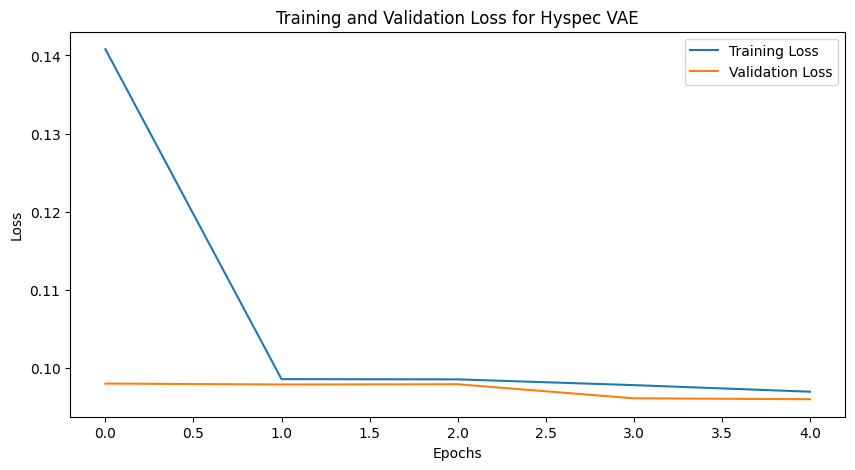

In [15]:
from net.hyspec_vae_net import hyspec_hsi_VAE, lr_reducer, early_stopping

hyspec_input_shape = (128, 128, 30)  # New input shape after PCA
pca_hyspec_hsi_vae = hyspec_hsi_VAE(hyspec_input_shape)

history = pca_hyspec_hsi_vae.fit(hyspec_train_gen,
                                 validation_data=hyspec_val_gen,
                                 epochs=5,
                                 verbose=1,
                                 callbacks=[lr_reducer, early_stopping])

plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss for Hyspec VAE')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

pca_hyspec_hsi_vae.save('models/pca_2D_hyspec_hsi_vae.keras')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Optimal number of clusters: 2


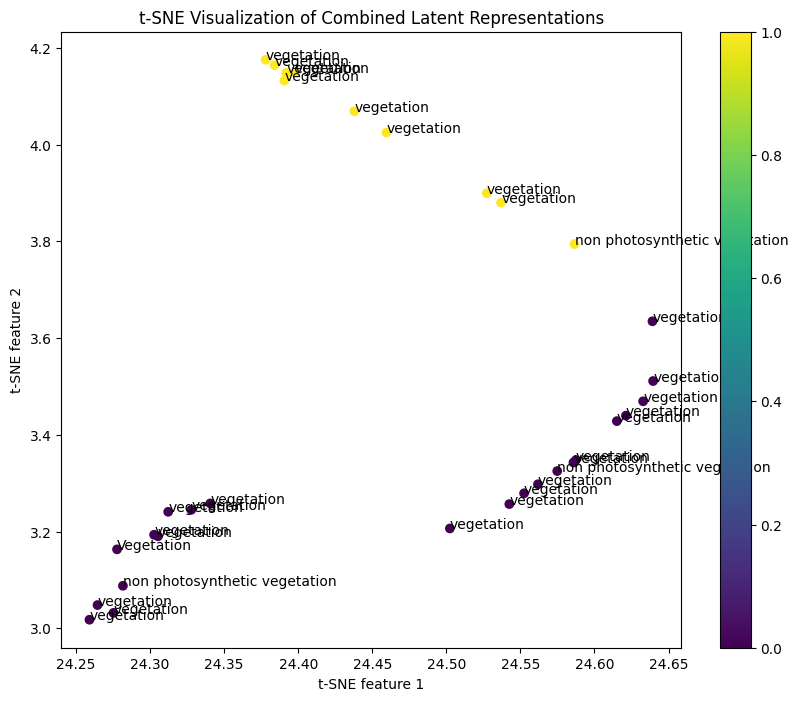

In [ ]:
from tensorflow.keras.models import Model
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt


hsi_data_batch = hyspec_test_gen[0][0]
spectral_data_subset = X_test[:hsi_data_batch.shape[0]]

hyspec_hsi_encoder_model = Model(inputs=pca_hyspec_hsi_vae.input, outputs=pca_hyspec_hsi_vae.get_layer('z_mean').output)
spectral_encoder_model = Model(inputs=spectral_VAE.input, outputs=spectral_VAE.get_layer('z_mean').output)

# Predict latent representations
hsi_latent = hsi_encoder_model.predict(hsi_data_batch)
spectral_latent = spectral_encoder_model.predict(spectral_data_subset)

combined_latent = np.concatenate([hsi_latent, spectral_latent], axis=1)


def find_optimal_clusters(data, max_k):
    n_samples = data.shape[0]
    if max_k >= n_samples:
        max_k = n_samples - 1  
        if max_k < 2:
            raise ValueError("Not enough data samples to form more than one cluster.")
    wcss = []
    silhouette_scores = []
    k_values = list(range(2, max_k + 1))

    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=42)
        cluster_labels = kmeans.fit_predict(data)
        wcss.append(kmeans.inertia_)
        silhouette_scores.append(silhouette_score(data, cluster_labels))

    elbow_value = np.argmin(np.gradient(wcss))
    optimal_k = k_values[elbow_value + np.argmax(silhouette_scores[elbow_value:])]

    return optimal_k, wcss, silhouette_scores


optimal_k, _, _ = find_optimal_clusters(combined_latent, max_k=20)
print(f"Optimal number of clusters: {optimal_k}")

# Perform KMeans clustering with the optimal number of clusters found
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
cluster_labels = kmeans.fit_predict(combined_latent)

# Perform t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(combined_latent)


plt.figure(figsize=(10, 8))
scatter = plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=cluster_labels, cmap='viridis')
plt.colorbar()


for i, txt in enumerate(cluster_labels):
    plt.annotate(spectral_df['Type'].iloc[i], (tsne_results[i, 0], tsne_results[i, 1]))

plt.xlabel('t-SNE feature 1')
plt.ylabel('t-SNE feature 2')
plt.title('t-SNE Visualization of Combined Latent Representations')
plt.show()


## Prediction and Analysis

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step


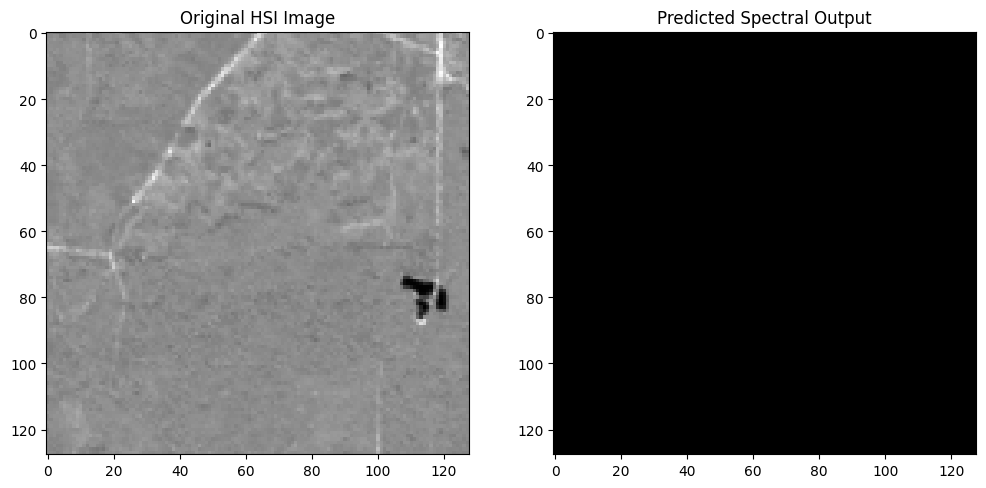

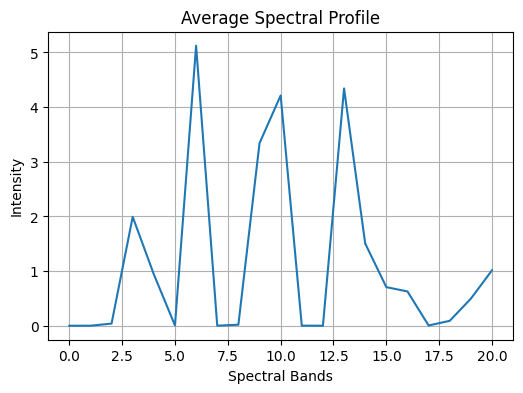

In [38]:
from tensorflow.keras.models import Model
import numpy as np
import matplotlib.pyplot as plt

# Load a single image from the test generator
hsi_image_batch, _ = hyspec_test_gen[0]  
hsi_single_image = hsi_image_batch[6] 

hsi_single_image = np.expand_dims(hsi_single_image, axis=0)

# Use the VAE model to predict the output from the single image
hsi_encoder_model = Model(inputs=pca_hyspec_hsi_vae.input, outputs=pca_hyspec_hsi_vae.get_layer('conv2d_transpose_6').output)
predicted_spectra = hsi_encoder_model.predict(hsi_single_image)

# Initialize a list to hold the spectral profiles
spectral_profiles = []

# Iterate over each pixel in the image
# spectral_profiles is a list of numpy arrays, where each array represents the spectral profile of a pixel
for i in range(predicted_spectra.shape[1]):  # Height index
    for j in range(predicted_spectra.shape[2]):  # Width index
        # Extract the spectral profile for this pixel
        spectral_profile = predicted_spectra[0, i, j, :]
        spectral_profiles.append(spectral_profile)


plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(hsi_single_image[0, :, :, 0], cmap='gray') 
plt.title('Original HSI Image')
plt.subplot(1, 2, 2)
plt.imshow(predicted_spectra[0, :, :, 0], cmap='gray') 
plt.title('Predicted Spectral Output')
plt.show()

# Average Spectral Profile
mean_spectral_profile = np.mean(np.array(spectral_profiles), axis=0)

# Plot the average spectral profile
plt.figure(figsize=(6, 4))
plt.plot(mean_spectral_profile)
plt.title('Average Spectral Profile')
plt.xlabel('Spectral Bands')
plt.ylabel('Intensity')
plt.grid(True)
plt.show()


[[[[0.         0.         0.2274351  ... 0.         0.
    0.62867767]
   [0.         0.         0.         ... 0.6089939  0.
    1.6255106 ]
   [0.         0.         1.1967059  ... 2.7784932  0.
    1.9801863 ]
   ...
   [0.         0.         0.133305   ... 1.3437825  0.
    1.7066771 ]
   [0.         0.         0.581019   ... 1.0806957  0.
    2.007729  ]
   [0.         0.3856875  0.43719083 ... 2.9095168  0.
    1.8388034 ]]

  [[0.         0.         1.8950016  ... 0.         0.
    1.0637816 ]
   [0.         0.         0.25012672 ... 0.         1.2733424
    0.        ]
   [0.         0.         0.         ... 2.4028962  0.473928
    0.        ]
   ...
   [0.         0.         0.         ... 0.         0.
    1.7913679 ]
   [0.         0.         0.40375656 ... 0.         0.
    1.2362376 ]
   [0.         0.         0.00752073 ... 1.0633478  0.42312336
    0.        ]]

  [[0.         0.         0.38369668 ... 0.3087652  3.6340752
    3.8350532 ]
   [0.         0.         0.   

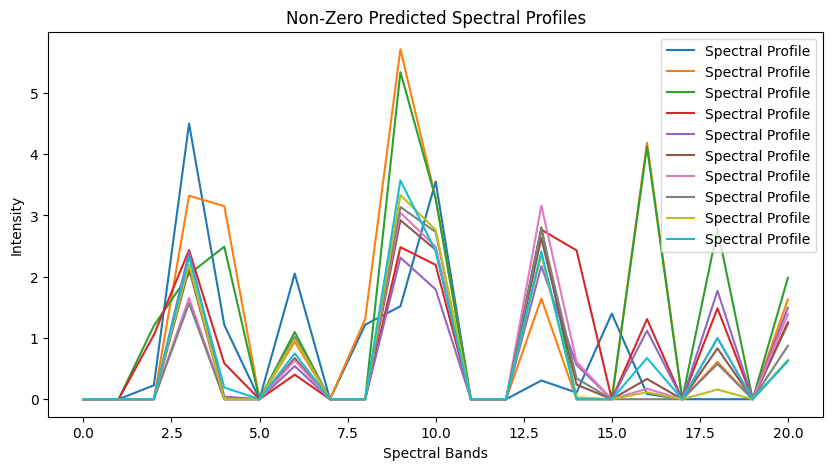

In [21]:
# Print the shape of the predictions array
print(predicted_spectra.shape)

# Print summary statistics
print("Min value:", predicted_spectra.min())
print("Max value:", predicted_spectra.max())
print("Mean value:", predicted_spectra.mean())
print("Standard Deviation:", predicted_spectra.std())

# Print a subset of the array (e.g., values from the first image)
print(predicted_spectra[0, :, :, 0]) 

# Print a specific prediction value
row_index = 10  # example row index
col_index = 10  # example column index
print("Specific pixel prediction:", predicted_spectra[0, row_index, col_index, :])


# Filter out zero-only spectral profiles
non_zero_profiles = [profile for profile in spectral_profiles if not np.all(profile == 0)]

# Plot a few non-zero spectral profiles
plt.figure(figsize=(10, 5))
for profile in non_zero_profiles[:10]:  # adjust the slice as needed
    plt.plot(profile, label='Spectral Profile')
plt.xlabel('Spectral Bands')
plt.ylabel('Intensity')
plt.title('Non-Zero Predicted Spectral Profiles')
plt.legend()
plt.show()

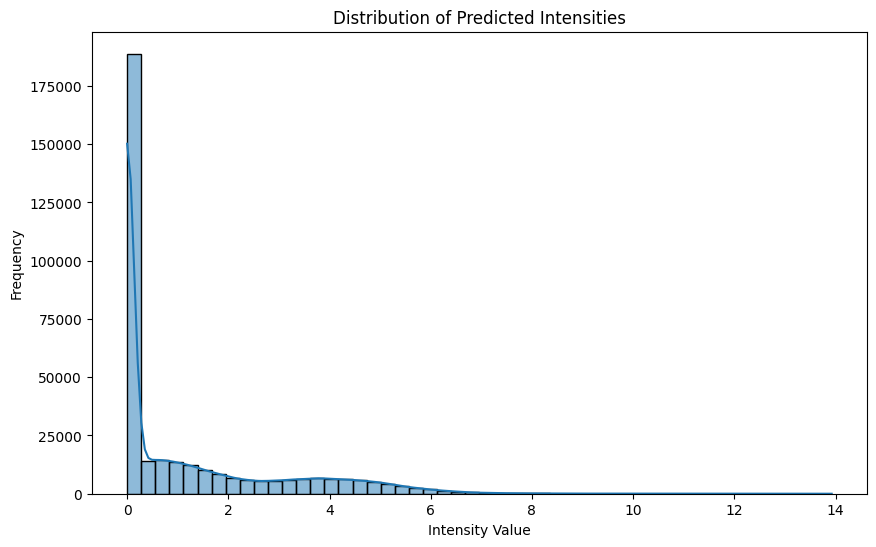

Active Bands: [ 1  2  3  4  5  6  7  8  9 10 11 13 14 15 16 17 18 19 20]


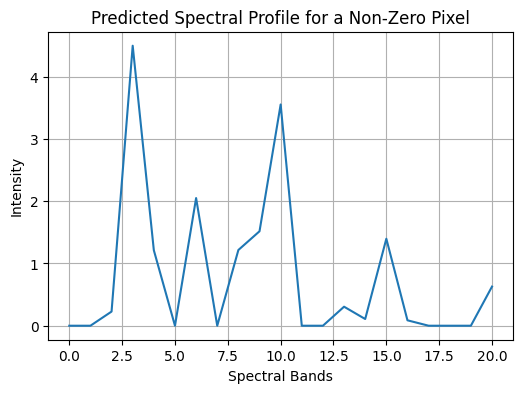

In [22]:
import seaborn as sns

# Flatten the predicted spectra to get the intensity values across all bands and pixels
predicted_intensities = predicted_spectra.flatten()

# Plot a histogram/density plot of predicted intensities
plt.figure(figsize=(10, 6))
sns.histplot(predicted_intensities, bins=50, kde=True)
plt.title('Distribution of Predicted Intensities')
plt.xlabel('Intensity Value')
plt.ylabel('Frequency')
plt.show()

# Check for any non-zero predictions across the bands
active_bands = np.any(predicted_spectra > 0, axis=(0, 1, 2))
print("Active Bands:", np.where(active_bands)[0])

# Example: Plot the spectral profile for the first pixel with a non-zero prediction
non_zero_pixels = np.where(predicted_spectra > 0)
first_non_zero_pixel = non_zero_pixels[0][0], non_zero_pixels[1][0], non_zero_pixels[2][0]
predicted_profile = predicted_spectra[first_non_zero_pixel]

plt.figure(figsize=(6, 4))
plt.plot(predicted_profile)
plt.title('Predicted Spectral Profile for a Non-Zero Pixel')
plt.xlabel('Spectral Bands')
plt.ylabel('Intensity')
plt.grid(True)
plt.show()


In [ ]:
# If `hsi_single_image` is the image with shape (1, 128, 128, 30) and you want to average over spatial dimensions
mean_spectral_profile = np.mean(hsi_single_image, axis=(1, 2))
# Padding to match the input shape of the spectral VAE
if mean_spectral_profile.shape[1] < 224:
    padding = 224 - mean_spectral_profile.shape[1]
    mean_spectral_profile_padded = np.pad(mean_spectral_profile, ((0, 0), (0, padding)), 'constant', constant_values=0)
    mean_spectral_profile_padded = np.expand_dims(mean_spectral_profile_padded, -1)  # Adding the last dimension for channel
else:
    # If `mean_spectral_profile` already has 224 features or more, select the first 224 features
    mean_spectral_profile_padded = mean_spectral_profile[:, :224, np.newaxis]


# Get the latent representation from the hsi_vae for the single image
hsi_latent_model = Model(inputs=pca_hyspec_hsi_vae.input, outputs=pca_hyspec_hsi_vae.get_layer('z_mean').output)
hsi_latent_representation = hsi_latent_model.predict(hsi_single_image)

# Prepare the mean spectral profile for the spec_vae
spec_latent_model = Model(inputs=spectral_VAE.input, outputs=spectral_VAE.get_layer('z_mean').output)

# use padded mean spectral profile
spec_latent_representation = spec_latent_model.predict(mean_spectral_profile_padded)

from sklearn.metrics.pairwise import cosine_similarity

# shapes of hsi_latent_representation and spec_latent_representation need to be compatible
# for cosine similarity calculation.
cosine_sim = cosine_similarity(hsi_latent_representation, spec_latent_representation)
print(f"Cosine similarity between HSI and Spectral VAE latent representations: {cosine_sim}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
Cosine similarity between HSI and Spectral VAE latent representations: [[-0.5537362]]
